In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import Normalize

In [15]:


pd.set_option("display.max_columns", 100)

# ============================================================
# PATHS
# ============================================================

MPING_PATH = "/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"

AI_BASE = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
MODEL_DIRS = {
    "Aurora": AI_BASE / "au_ptype",
    "GraphCast": AI_BASE / "gc_ptype",
    "Pangu-Weather": AI_BASE / "pw_ptype",
    "WXFormer": AI_BASE / "wx_ptype",
    "FuXi": AI_BASE / "fuxi_ptype",
    "GFS": Path("/glade/derecho/scratch/sakor/gfs/processed"),
}
F = Path("/glade/work/sakor/AI_NWP")
OUT = AI_BASE / "verification_multimodel"
FIG = F / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ============================================================
# EXPERIMENT
# ============================================================

START = pd.Timestamp("2021-12-01 00:00:00")
END = pd.Timestamp("2022-04-01 00:00:00")  # exclusive
CONSENSUS = 70.0

LAT_MIN, LAT_MAX = 24.0, 50.0
LON_MIN, LON_MAX = -125.0, -66.0
MAX_DIST_KM = 30.0

PTYPE_COLS = {
    "sn_percent": "Snow",
    "ra_percent": "Rain",
    "pl_percent": "Ice Pellet",
    "fzra_percent": "Freezing Rain",
}

CLASS_NAMES = {0: "Rain", 1: "Snow", 2: "Ice Pellet", 3: "Freezing Rain"}
CLASS_CODES = {v: k for k, v in CLASS_NAMES.items()}
CLASS_ORDER = ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]
FRZR_IP_CLASSES = ["Ice Pellet", "Freezing Rain"]

EPI_VARS = {
    "Rain": "ML_rain_epi", "Snow": "ML_snow_epi",
    "Ice Pellet": "ML_icep_epi", "Freezing Rain": "ML_frzr_epi",
}
ALE_VARS = {
    "Rain": "ML_rain_ale", "Snow": "ML_snow_ale",
    "Ice Pellet": "ML_icep_ale", "Freezing Rain": "ML_frzr_ale",
}

EXTRACT_VARS = [
    "ML_ptype",
    "ML_rain_ale", "ML_snow_ale", "ML_icep_ale", "ML_frzr_ale",
    "ML_rain_epi", "ML_snow_epi", "ML_icep_epi", "ML_frzr_epi",
    "BOURG_ptype", "GFS_ptype",
]


## Mping QC

In [3]:
def prepare_mping(path):
    cols = ["datetime","lat","lon","report_count","sn_percent","ra_percent","pl_percent","fzra_percent"]
    d = pd.read_parquet(path, columns=cols)
    d["datetime"] = pd.to_datetime(d["datetime"])

    d = d[(d.datetime >= START) & (d.datetime < END)].copy()
    d = d[d.datetime.dt.hour.isin([0,6,12,18])].copy()
    d = d[d.lat.between(LAT_MIN,LAT_MAX) & d.lon.between(LON_MIN,LON_MAX)].copy()

    pcols = list(PTYPE_COLS)
    d["obs_class"] = d[pcols].idxmax(axis=1).map(PTYPE_COLS)
    d["obs_consensus"] = d[pcols].max(axis=1)
    if d.obs_consensus.max() <= 1:
        d["obs_consensus"] *= 100

    d = d[d.obs_consensus >= CONSENSUS].reset_index(drop=True)
    d["obs_id"] = np.arange(len(d), dtype=np.int64)
    return d[["obs_id","datetime","lat","lon","report_count","obs_class","obs_consensus"]]

def expand_forecast_days(obs):
    out = []
    for day in range(1,8):
        x = obs.copy()
        h = x.datetime.dt.hour
        x["forecast_day"] = day
        x["lead_hour"] = np.where(h == 0, 24*day, h + 24*(day-1)).astype(np.int16)
        x["init_time"] = x.datetime - pd.to_timedelta(x.lead_hour, unit="h")
        out.append(x)
    return pd.concat(out, ignore_index=True)

obs = prepare_mping(MPING_PATH)
master = expand_forecast_days(obs)

assert master.groupby("obs_id").size().eq(7).all()
assert not (master.lead_hour == 0).any()

print(f"mPING observations after >=70% QC: {len(obs):,}")
print(f"Expanded verification rows: {len(master):,}")
print("\nLead hours by forecast day:")
print(master.groupby("forecast_day").lead_hour.apply(lambda x: sorted(x.unique())))
print("\nObserved classes:")
print(obs.obs_class.value_counts().reindex(CLASS_ORDER))


mPING observations after >=70% QC: 29,834
Expanded verification rows: 208,838

Lead hours by forecast day:
forecast_day
1         [6, 12, 18, 24]
2        [30, 36, 42, 48]
3        [54, 60, 66, 72]
4        [78, 84, 90, 96]
5    [102, 108, 114, 120]
6    [126, 132, 138, 144]
7    [150, 156, 162, 168]
Name: lead_hour, dtype: object

Observed classes:
obs_class
Rain             11902
Snow             15894
Ice Pellet        1220
Freezing Rain      818
Name: count, dtype: int64


## File Directory

In [4]:
FILE_PREFIX = {
    "Aurora": "aurora",
    "GraphCast": "graphcast",
    "Pangu-Weather": "pangu",
    "WXFormer": "wxformer",
    "FuXi":"fuxi",
    "GFS": "gfs",
}

def init_string(t):
    return pd.Timestamp(t).strftime("%Y-%m-%dT00Z")

def resolve_file(model, init_time, lead_hour):
    s = init_string(init_time)
    folder = MODEL_DIRS[model] / s
    lead = f"{int(lead_hour):03d}"

    expected = folder / f"{FILE_PREFIX[model]}_{s}_{lead}.nc"
    if expected.exists():
        return expected

    hits = sorted(folder.glob(f"*_{lead}.nc"))
    if len(hits) == 1:
        return hits[0]
    if len(hits) == 0:
        return None

    raise RuntimeError(f"Ambiguous files for {model}, {s}, +{lead} h: {hits}")

# Quick file-coverage check before expensive collocation
required = master[["init_time","lead_hour"]].drop_duplicates().sort_values(["init_time","lead_hour"])
coverage = []

for model in MODEL_DIRS:
    for r in required.itertuples(index=False):
        p = resolve_file(model, r.init_time, r.lead_hour)
        coverage.append({
            "model": model, "init_time": r.init_time, "lead_hour": r.lead_hour,
            "exists": p is not None, "path": str(p) if p else None
        })

coverage = pd.DataFrame(coverage)
display(coverage.groupby("model").exists.agg(["sum","count"]))
print("\nMissing files by model:")
display(coverage[~coverage.exists].groupby("model").size())


,sum,count
model,,
Aurora,3325,3325
FuXi,3325,3325
GFS,3325,3325
GraphCast,3325,3325
Pangu-Weather,3325,3325
WXFormer,3325,3325



Missing files by model:


Series([], dtype: int64)

## Generic nearest-grid collocation

In [5]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1,lon1,lat2,lon2])
    dlat, dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

def extract_points(ds, group, model):
    q = ds.sel(
        latitude=xr.DataArray(group.lat.to_numpy(), dims="obs"),
        longitude=xr.DataArray(group.lon.to_numpy(), dims="obs"),
        method="nearest"
    )

    r = group.reset_index(drop=True).copy()
    r["model"] = model
    r["grid_lat"] = np.asarray(q.latitude).squeeze()
    r["grid_lon"] = np.asarray(q.longitude).squeeze()
    r["grid_distance_km"] = haversine(
        r.lat.to_numpy(), r.lon.to_numpy(),
        r.grid_lat.to_numpy(), r.grid_lon.to_numpy()
    )
    r["spatial_match_valid"] = r.grid_distance_km <= MAX_DIST_KM

    for var in EXTRACT_VARS:
        if var in q:
            r[var] = np.asarray(q[var]).squeeze()

    return r

def collocate_model(model, master):
    out = []
    groups = master.groupby(["init_time","lead_hour"], sort=True)
    n = len(groups)

    for i, ((init_time, lead_hour), g) in enumerate(groups, 1):
        path = resolve_file(model, init_time, lead_hour)
        if path is None:
            print(f"[MISSING] {model}: {init_string(init_time)} +{lead_hour:03d}")
            continue

        if i == 1 or i % 100 == 0 or i == n:
            print(f"{model}: {i}/{n} | {init_string(init_time)} +{lead_hour:03d} | N={len(g)}")

        with xr.open_dataset(path, decode_timedelta=False) as ds:
            out.append(extract_points(ds, g, model))

    if not out:
        raise RuntimeError(f"No files collocated for {model}")

    d = pd.concat(out, ignore_index=True)
    d.to_parquet(OUT / f"{model.lower().replace('-','_')}_mping_collocations.parquet", index=False)
    return d


In [6]:
collocated = {}

for model in ["Aurora", "GraphCast", "Pangu-Weather", "GFS","WXFormer", "FuXi"]:

    save_file = OUT / f"{model.lower().replace('-', '_')}_mping_collocations.parquet"

    if save_file.exists():
        print(f"Loading existing collocations: {model}")
        collocated[model] = pd.read_parquet(save_file)

    else:
        print(f"Generating collocations: {model}")
        collocated[model] = collocate_model(model, master)

    print(f"  {len(collocated[model]):,} rows")


Loading existing collocations: Aurora
  208,838 rows
Loading existing collocations: GraphCast
  208,838 rows
Loading existing collocations: Pangu-Weather
  208,838 rows
Loading existing collocations: GFS
  208,838 rows
Loading existing collocations: WXFormer
  208,838 rows
Loading existing collocations: FuXi
  208,838 rows


## Collocation QC 

In [7]:
qc_rows = []

for model, d in collocated.items():
    qc_rows.append({
        "Model": model,
        "Rows": len(d),
        "Median distance km": d.grid_distance_km.median(),
        "95th distance km": d.grid_distance_km.quantile(.95),
        "Max distance km": d.grid_distance_km.max(),
        ">30 km": (~d.spatial_match_valid).sum(),
        "ML invalid": (~d.ML_ptype.isin(CLASS_NAMES)).sum() if "ML_ptype" in d else np.nan,
        "Bourg invalid": (~d.BOURG_ptype.isin(CLASS_NAMES)).sum() if "BOURG_ptype" in d else np.nan,
        "GFS native invalid": (~d.GFS_ptype.isin(CLASS_NAMES)).sum() if "GFS_ptype" in d else np.nan,
    })

qc = pd.DataFrame(qc_rows)
display(qc.round(3))
qc.to_csv(OUT/"collocation_qc.csv", index=False)


,Model,Rows,Median distance km,95th distance km,Max distance km,>30 km,ML invalid,Bourg invalid,GFS native invalid
0,Aurora,208838,9.736,15.011,18.234,0,148,0,NaN
1,GraphCast,208838,9.736,15.011,18.234,0,758,0,NaN
2,Pangu-Weather,208838,9.736,15.011,18.234,0,1330,0,NaN
3,GFS,208838,9.736,15.011,18.234,0,0,0,98280.0
4,WXFormer,208838,10.850,16.799,19.997,0,0,0,NaN
5,FuXi,208838,10.850,16.799,19.997,0,0,0,NaN


## Convert to a unified diagnostic table

In [8]:
SYSTEMS = [
    ("Aurora",        "EDNN",      "ML_ptype"),
    ("Aurora",        "Bourgouin", "BOURG_ptype"),
    ("GraphCast",     "EDNN",      "ML_ptype"),
    ("GraphCast",     "Bourgouin", "BOURG_ptype"),
    ("WXFormer",     "EDNN",      "ML_ptype"),
    ("WXFormer",     "Bourgouin", "BOURG_ptype"),
    ("FuXi",     "EDNN",      "ML_ptype"),
    ("FuXi",     "Bourgouin", "BOURG_ptype"),
    ("Pangu-Weather", "EDNN",      "ML_ptype"),
    ("Pangu-Weather", "Bourgouin", "BOURG_ptype"),
    ("GFS",           "Native",    "GFS_ptype"),
    ("GFS",           "EDNN",      "ML_ptype"),
]

SYSTEM_ORDER = [
    "Aurora — EDNN",
    "Aurora — Bourgouin",
    "GraphCast — EDNN",
    "GraphCast — Bourgouin",
    "WXFormer — EDNN",
    "WXFormer — Bourgouin",
    "FuXi — EDNN",
    "FuXi — Bourgouin",
    "Pangu-Weather — EDNN",
    "Pangu-Weather — Bourgouin",
    "GFS — Native",
    "GFS — EDNN",
]


# ============================================================
# BUILD UNIFIED PREDICTION TABLE
# ============================================================

frames = []

for model, method, pred_col in SYSTEMS:

    d = collocated[model]

    keep = [
        "obs_id",
        "datetime",
        "lat",
        "lon",
        "obs_class",
        "obs_consensus",
        "forecast_day",
        "lead_hour",
        "init_time",
        "grid_distance_km",
        "spatial_match_valid",
        pred_col,
    ]

    x = d[keep].copy()

    x = x.rename(columns={
        pred_col: "pred_code"
    })

    x["Model"] = model
    x["Method"] = method
    x["System"] = f"{model} — {method}"

    frames.append(x)


predictions = pd.concat(
    frames,
    ignore_index=True
)


# ============================================================
# OBSERVED CLASS CODE
# ============================================================

predictions["obs_code"] = (
    predictions["obs_class"]
    .map(CLASS_CODES)
    .astype(int)
)


# ============================================================
# FORECAST AVAILABILITY / VALIDITY
# ============================================================

# Default behavior:
# EDNN and Bourgouin must return one of the four ptype classes.
predictions["pred_available"] = (
    predictions["pred_code"]
    .isin([0, 1, 2, 3])
)


# Native GFS is different:
# -1 = no precipitation type diagnosed.
# This is a legitimate native-GFS forecast, not missing data.
is_gfs_native = (
    (predictions["Model"] == "GFS") &
    (predictions["Method"] == "Native")
)

predictions.loc[
    is_gfs_native,
    "pred_available"
] = (
    predictions.loc[
        is_gfs_native,
        "pred_code"
    ]
    .isin([-1, 0, 1, 2, 3])
)


# Optional convenience flag for native GFS
predictions["gfs_native_none"] = False

predictions.loc[
    is_gfs_native,
    "gfs_native_none"
] = (
    predictions.loc[
        is_gfs_native,
        "pred_code"
    ] == -1
)


# ============================================================
# SUMMARY / QC
# ============================================================

summary = (
    predictions
    .groupby("System")
    .agg(
        rows=("obs_id", "size"),
        spatial_valid=("spatial_match_valid", "sum"),
        pred_available=("pred_available", "sum"),
        no_precip_native_gfs=("gfs_native_none", "sum"),
    )
    .reindex(SYSTEM_ORDER)
)

display(summary)

,rows,spatial_valid,pred_available,no_precip_native_gfs
System,,,,
Aurora — EDNN,208838,208838,208690,0
Aurora — Bourgouin,208838,208838,208838,0
GraphCast — EDNN,208838,208838,208080,0
GraphCast — Bourgouin,208838,208838,208838,0
WXFormer — EDNN,208838,208838,208838,0
WXFormer — Bourgouin,208838,208838,208838,0
FuXi — EDNN,208838,208838,208838,0
FuXi — Bourgouin,208838,208838,208838,0
Pangu-Weather — EDNN,208838,208838,207508,0


## Construct the common-valid sample

In [9]:

# ============================================================
# COMMON-VALID SAMPLE ACROSS ALL SYSTEMS
# ============================================================

predictions["row_valid"] = (
    predictions["spatial_match_valid"] &
    predictions["pred_available"]
)

valid_counts = (
    predictions
    .groupby(["obs_id", "forecast_day"])
    .agg(
        n_systems=("System", "nunique"),
        n_valid=("row_valid", "sum"),
    )
    .reset_index()
)

common_keys = valid_counts[
    (valid_counts["n_systems"] == len(SYSTEM_ORDER)) &
    (valid_counts["n_valid"] == len(SYSTEM_ORDER))
][["obs_id", "forecast_day"]]

common = predictions.merge(
    common_keys,
    on=["obs_id", "forecast_day"],
    how="inner"
).copy()

common["pred_code"] = common["pred_code"].astype(int)

print(f"Common observation/day keys: {len(common_keys):,}")
print(f"Rows in unified common table: {len(common):,}")

print("\nCommon observations per forecast day:")
print(
    common_keys
    .groupby("forecast_day")
    .size()
)

# QC: every retained obs/day must contain all requested systems
assert (
    common
    .groupby(["obs_id", "forecast_day"])["System"]
    .nunique()
    .eq(len(SYSTEM_ORDER))
    .all()
)

# Optional: verify native GFS -1 forecasts are retained
print("\nNative GFS no-ptype forecasts retained:")
print(
    common.loc[
        common["System"] == "GFS — Native",
        "gfs_native_none"
    ].value_counts()
)

common.to_parquet(
    OUT / "common_valid_multimodel_predictions.parquet",
    index=False
)


Common observation/day keys: 206,786
Rows in unified common table: 2,481,432

Common observations per forecast day:
forecast_day
1    29536
2    29546
3    29560
4    29532
5    29514
6    29590
7    29508
dtype: int64

Native GFS no-ptype forecasts retained:
gfs_native_none
False    109746
True      97040
Name: count, dtype: int64


## Forecast verification metrics

In [10]:
def safe_div(a,b):
    return np.nan if b == 0 else a/b

def class_metrics(obs, pred, c):
    obs, pred = np.asarray(obs), np.asarray(pred)
    o, p = obs == c, pred == c
    tp = np.sum(o&p); fn = np.sum(o&~p); fp = np.sum(~o&p); tn = np.sum(~o&~p)
    return {
        "N": len(obs), "Observed": int(tp+fn), "Forecast": int(tp+fp),
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
        "POD": safe_div(tp,tp+fn),
        "FAR": safe_div(fp,tp+fp),
        "CSI": safe_div(tp,tp+fn+fp),
        "Frequency_Bias": safe_div(tp+fp,tp+fn),
    }

rows = []
for system in SYSTEM_ORDER:
    s = common[common.System == system]
    for day in range(1,8):
        d = s[s.forecast_day == day]
        for c, ptype in CLASS_NAMES.items():
            r = class_metrics(d.obs_code, d.pred_code, c)
            r.update(System=system, Forecast_Day=day, Class=ptype)
            rows.append(r)

skill = pd.DataFrame(rows)
skill.to_csv(OUT/"multimodel_skill_by_day.csv", index=False)
display(skill.head())


,N,Observed,Forecast,TP,FN,FP,TN,POD,FAR,CSI,Frequency_Bias,System,Forecast_Day,Class
0,29536,11870,11486,10804,1066,682,16984,0.910194,0.059377,0.860739,0.967650,Aurora — EDNN,1,Rain
1,29536,15634,16436,15080,554,1356,12546,0.964564,0.082502,0.887581,1.051298,Aurora — EDNN,1,Snow
2,29536,1216,742,478,738,264,28056,0.393092,0.355795,0.322973,0.610197,Aurora — EDNN,1,Ice Pellet
3,29536,816,872,360,456,512,28208,0.441176,0.587156,0.271084,1.068627,Aurora — EDNN,1,Freezing Rain
4,29546,11878,11790,10768,1110,1022,16646,0.906550,0.086684,0.834729,0.992591,Aurora — EDNN,2,Rain


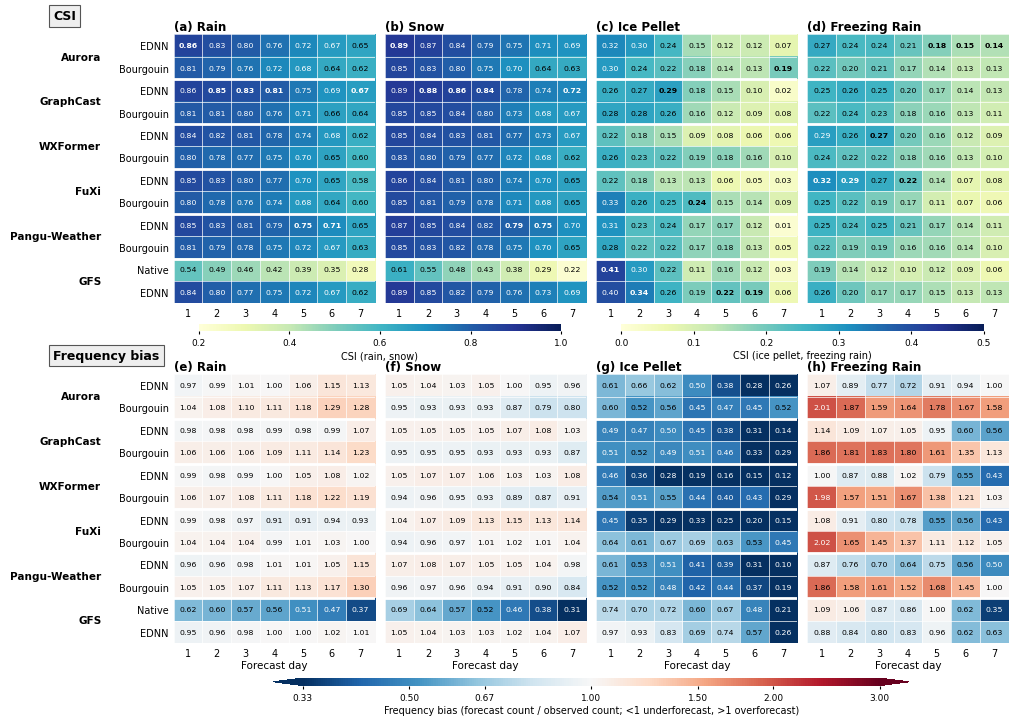

In [20]:
# ============================================================
# 1. Frequency bias per System / Forecast_Day / Class
#    bias = (# forecasts of class) / (# observations of class)
#    Uses the same valid-sample mask you should be using for CSI.
#    Skip this block if `skill` already has a Bias column.
# ============================================================
valid = predictions[
    predictions["spatial_match_valid"].astype(bool)
    & predictions["pred_available"].astype(bool)
]
rows = []
for (system, day), g in valid.groupby(["System", "forecast_day"]):
    for cls in CLASS_ORDER:
        code = CLASS_CODES[cls]
        n_obs = (g["obs_code"] == code).sum()
        n_fcst = (g["pred_code"] == code).sum()
        rows.append({
            "System": system, "Forecast_Day": day, "Class": cls,
            "Bias": n_fcst / n_obs if n_obs > 0 else np.nan,
        })
bias_df = pd.DataFrame(rows)
skill = skill.drop(columns="Bias", errors="ignore").merge(
    bias_df, on=["System", "Forecast_Day", "Class"], how="left"
)

# ============================================================
# 2. Figure: row 1 = CSI, row 2 = frequency bias
# ============================================================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 7.5,
    "axes.titlesize": 8.5,
    "axes.labelsize": 7.5,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

n_sys, n_day, n_cls = len(SYSTEM_ORDER), 7, len(CLASS_ORDER)
models  = [s.split(" — ")[0] for s in SYSTEM_ORDER]
methods = [s.split(" — ")[1] for s in SYSTEM_ORDER]
starts = [i for i in range(n_sys) if i == 0 or models[i] != models[i - 1]]
bounds = starts + [n_sys]

CSI_CMAP = plt.get_cmap("YlGnBu")
BIAS_CMAP = plt.get_cmap("RdBu_r")          # red = overforecast, blue = under
# CSI: frequent classes (rain, snow) and rare classes (IP, FZRA) get own scales
CSI_NORMS = [Normalize(0.2, 1.0)] * 2 + [Normalize(0.0, 0.5)] * 2
# Bias: plotted as log2 so 0.5x and 2x are equally far from 1
BIAS_LIM = np.log2(3)
BIAS_NORM = Normalize(-BIAS_LIM, BIAS_LIM)
BIAS_TICKS = [1/3, 1/2, 2/3, 1, 1.5, 2, 3]
BIAS_TICKLABELS = [f"{t:.2f}" for t in BIAS_TICKS]   # 0.33 ... 3.00, log-spaced

# Boxed style for the row labels ("CSI", "Frequency bias")
ROW_LABEL_BOX = dict(boxstyle="square,pad=0.35", facecolor="#eeeeee",
                     edgecolor="#555555", linewidth=0.8)

# Text color (black/white) is for legibility only, chosen from cell brightness.
def text_color(rgba):
    r, g, b = rgba[:3]
    return "black" if (0.299 * r + 0.587 * g + 0.114 * b) > 0.5 else "white"

def get_grid(cls, metric):
    return (
        skill[skill.Class == cls]
        .pivot(index="System", columns="Forecast_Day", values=metric)
        .reindex(SYSTEM_ORDER)
        .reindex(columns=range(1, n_day + 1))
    ).values

def style_axis(ax, col):
    ax.set_xticks(np.arange(-.5, n_day, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n_sys, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.5)
    for b in bounds[1:-1]:
        ax.axhline(b - 0.5, color="white", linewidth=2.0)
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xticks(np.arange(n_day), np.arange(1, n_day + 1))
    ax.set_yticks(np.arange(n_sys))
    if col == 0:
        ax.set_yticklabels(methods)
        for a, b in zip(bounds[:-1], bounds[1:]):
            ax.text(-0.36, (a + b - 1) / 2, models[a],
                    transform=ax.get_yaxis_transform(),
                    ha="right", va="center", fontweight="bold")
    else:
        ax.set_yticklabels([])

def annotate(ax, z, colors, best):
    for i in range(n_sys):
        for j in range(n_day):
            v = z[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                        fontsize=5.6, color=colors[i, j],
                        fontweight="bold" if best[j] == i else "normal")

fig = plt.figure(figsize=(10.0, 7.4))
# rows: CSI | tick space | CSI cbar | gap | Bias | tick space | Bias cbar
gs = GridSpec(7, n_cls, figure=fig,
              height_ratios=[1, 0.075, 0.028, 0.16, 1, 0.13, 0.028],
              hspace=0, wspace=0.05,
              left=0.155, right=0.99, bottom=0.075, top=0.955)

letters = "abcdefgh"
for c, cls in enumerate(CLASS_ORDER):
    # ---------------- CSI ----------------
    ax = fig.add_subplot(gs[0, c])
    z = get_grid(cls, "CSI")
    norm = CSI_NORMS[c]
    im_csi = ax.imshow(z, cmap=CSI_CMAP, norm=norm, aspect="auto",
                       interpolation="none")
    colors = np.vectorize(lambda v: text_color(CSI_CMAP(norm(v))) if np.isfinite(v) else "k",
                          otypes=[object])(z)
    annotate(ax, z, colors, np.nanargmax(z, axis=0))   # bold = highest CSI per day
    style_axis(ax, c)
    ax.set_title(f"({letters[c]}) {cls}", loc="left", fontweight="bold", pad=3)
    if c == 0:
        ax.text(-0.60, 1.045, "CSI", transform=ax.transAxes,
                fontsize=9, fontweight="bold", ha="left", va="bottom",
                bbox=ROW_LABEL_BOX)
    if c in (1, 3):   # one horizontal colorbar under each class pair
        cax = fig.add_subplot(gs[2, c - 1:c + 1])
        p = cax.get_position()   # inset so the two CSI colorbars don't touch
        cax.set_position([p.x0 + 0.025, p.y0, p.width - 0.05, p.height])
        cb = fig.colorbar(im_csi, cax=cax, orientation="horizontal",
                          ticks=np.arange(norm.vmin, norm.vmax + 1e-9, 0.1 if c == 3 else 0.2))
        cb.outline.set_visible(False)
        cb.ax.tick_params(length=2, labelsize=6.5)
        cb.set_label("CSI" + (" (rain, snow)" if c == 1 else " (ice pellet, freezing rain)"),
                     fontsize=7, labelpad=2)

    # ---------------- Frequency bias ----------------
    ax = fig.add_subplot(gs[4, c])
    zb = get_grid(cls, "Bias")
    lz = np.log2(zb)
    im_b = ax.imshow(lz, cmap=BIAS_CMAP, norm=BIAS_NORM, aspect="auto",
                     interpolation="none")
    colors = np.vectorize(lambda v: text_color(BIAS_CMAP(BIAS_NORM(v))) if np.isfinite(v) else "k",
                          otypes=[object])(lz)
    annotate(ax, zb, colors, np.full(n_day, -1))   # no bolding in bias row
    style_axis(ax, c)
    ax.set_xlabel("Forecast day", labelpad=2)
    ax.set_title(f"({letters[c + 4]}) {cls}", loc="left", fontweight="bold", pad=3)
    if c == 0:
        ax.text(-0.60, 1.045, "Frequency bias", transform=ax.transAxes,
                fontsize=9, fontweight="bold", ha="left", va="bottom",
                bbox=ROW_LABEL_BOX)

cax = fig.add_subplot(gs[6, :])
p = cax.get_position()
cax.set_position([p.x0 + 0.1, p.y0, p.width - 0.2, p.height])
cb = fig.colorbar(im_b, cax=cax, orientation="horizontal", extend="both",
                  ticks=np.log2(BIAS_TICKS))
cb.ax.set_xticklabels(BIAS_TICKLABELS)
cb.outline.set_visible(False)
cb.ax.tick_params(length=2, labelsize=6.5)
cb.set_label("Frequency bias (forecast count / observed count; <1 underforecast, >1 overforecast)",
             fontsize=7, labelpad=2)

fig.savefig(FIG / "multimodel_csi_bias_heatmap.pdf", dpi=400, bbox_inches="tight")
plt.show()

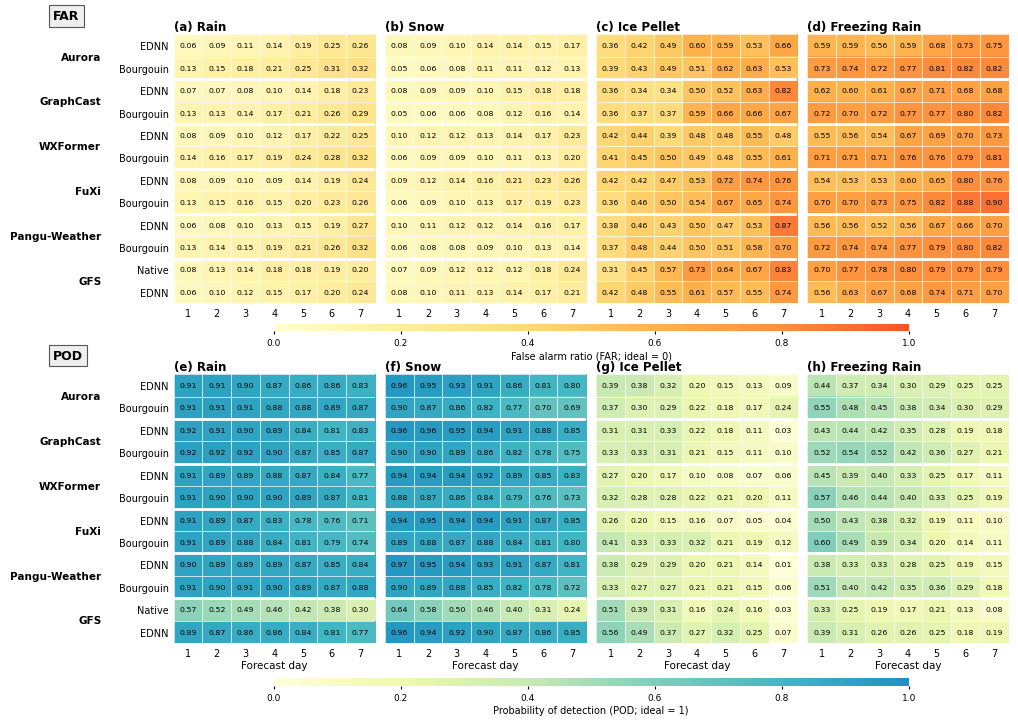

In [21]:


# ============================================================
# 1. FAR and POD per System / Forecast_Day / Class
#    For each class (one-vs-rest):
#      hits (H)         = forecast class & observed class
#      false alarms (F) = forecast class & observed other
#      misses (M)       = forecast other (incl. native GFS -1) & observed class
#    FAR = F / (H + F)   ideal 0   (undefined if class never forecast)
#    POD = H / (H + M)   ideal 1   (undefined if class never observed)
#    Same valid-sample mask as the CSI / bias figure.
# ============================================================
valid = predictions[
    predictions["spatial_match_valid"].astype(bool)
    & predictions["pred_available"].astype(bool)
]
rows = []
for (system, day), g in valid.groupby(["System", "forecast_day"]):
    for cls in CLASS_ORDER:
        code = CLASS_CODES[cls]
        obs_y = g["obs_code"] == code
        fc_y = g["pred_code"] == code
        H = (obs_y & fc_y).sum()
        F = (~obs_y & fc_y).sum()
        M = (obs_y & ~fc_y).sum()
        rows.append({
            "System": system, "Forecast_Day": day, "Class": cls,
            "FAR": F / (H + F) if (H + F) > 0 else np.nan,
            "POD": H / (H + M) if (H + M) > 0 else np.nan,
        })
far_pod = pd.DataFrame(rows)

# ============================================================
# 2. Figure: row 1 = FAR, row 2 = POD
# ============================================================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 7.5,
    "axes.titlesize": 8.5,
    "axes.labelsize": 7.5,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

n_sys, n_day, n_cls = len(SYSTEM_ORDER), 7, len(CLASS_ORDER)
models  = [s.split(" — ")[0] for s in SYSTEM_ORDER]
methods = [s.split(" — ")[1] for s in SYSTEM_ORDER]
starts = [i for i in range(n_sys) if i == 0 or models[i] != models[i - 1]]
bounds = starts + [n_sys]

def truncate_cmap(name, lo, hi, n=256):
    """Use only the lighter part of a colormap so black text stays readable."""
    return ListedColormap(plt.get_cmap(name)(np.linspace(lo, hi, n)))

# All cell values are printed in black; colormaps are trimmed accordingly.
# FAR: darker = more false alarms (worse). POD: darker = more detections (better).
FAR_CMAP = truncate_cmap("YlOrRd", 0.0, 0.62)
POD_CMAP = truncate_cmap("YlGnBu", 0.0, 0.62)
NORM = Normalize(0.0, 1.0)          # both are rates on [0, 1]; one scale per row
TICKS = np.arange(0.0, 1.01, 0.2)

# No bold "best" values: a system that rarely forecasts a class gets low FAR
# and low POD at the same time, so neither metric alone identifies the best system.

ROW_LABEL_BOX = dict(boxstyle="square,pad=0.35", facecolor="#eeeeee",
                     edgecolor="#555555", linewidth=0.8)

def get_grid(metric, cls):
    return (
        far_pod[far_pod.Class == cls]
        .pivot(index="System", columns="Forecast_Day", values=metric)
        .reindex(SYSTEM_ORDER)
        .reindex(columns=range(1, n_day + 1))
    ).values

def style_axis(ax, col):
    ax.set_xticks(np.arange(-.5, n_day, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n_sys, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.5)
    for b in bounds[1:-1]:
        ax.axhline(b - 0.5, color="white", linewidth=2.0)
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xticks(np.arange(n_day), np.arange(1, n_day + 1))
    ax.set_yticks(np.arange(n_sys))
    if col == 0:
        ax.set_yticklabels(methods)
        for a, b in zip(bounds[:-1], bounds[1:]):
            ax.text(-0.36, (a + b - 1) / 2, models[a],
                    transform=ax.get_yaxis_transform(),
                    ha="right", va="center", fontweight="bold")
    else:
        ax.set_yticklabels([])

def annotate(ax, z):
    for i in range(n_sys):
        for j in range(n_day):
            v = z[i, j]
            ax.text(j, i, f"{v:.2f}" if np.isfinite(v) else "–",
                    ha="center", va="center", fontsize=5.6, color="black")

fig = plt.figure(figsize=(10.0, 7.4))
# rows: FAR | tick space | FAR cbar | gap | POD | tick space | POD cbar
gs = GridSpec(7, n_cls, figure=fig,
              height_ratios=[1, 0.075, 0.028, 0.16, 1, 0.13, 0.028],
              hspace=0, wspace=0.05,
              left=0.155, right=0.99, bottom=0.075, top=0.955)

ROWS = [
    # (metric, grid row, cbar row, cmap, row label, colorbar label, first letter idx)
    ("FAR", 0, 2, FAR_CMAP, "FAR", "False alarm ratio (FAR; ideal = 0)", 0),
    ("POD", 4, 6, POD_CMAP, "POD", "Probability of detection (POD; ideal = 1)", 4),
]
letters = "abcdefgh"

for metric, grow, crow, cmap, row_label, cbar_label, l0 in ROWS:
    for c, cls in enumerate(CLASS_ORDER):
        ax = fig.add_subplot(gs[grow, c])
        z = get_grid(metric, cls)
        im = ax.imshow(z, cmap=cmap, norm=NORM, aspect="auto",
                       interpolation="none")
        annotate(ax, z)
        style_axis(ax, c)
        ax.set_title(f"({letters[l0 + c]}) {cls}", loc="left",
                     fontweight="bold", pad=3)
        if grow == 4:
            ax.set_xlabel("Forecast day", labelpad=2)
        if c == 0:
            ax.text(-0.60, 1.045, row_label, transform=ax.transAxes,
                    fontsize=9, fontweight="bold", ha="left", va="bottom",
                    bbox=ROW_LABEL_BOX)

    cax = fig.add_subplot(gs[crow, :])
    p = cax.get_position()
    cax.set_position([p.x0 + 0.1, p.y0, p.width - 0.2, p.height])
    cb = fig.colorbar(im, cax=cax, orientation="horizontal", ticks=TICKS)
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=2, labelsize=6.5)
    cb.set_label(cbar_label, fontsize=7, labelpad=2)

fig.savefig(FIG / "multimodel_far_pod_heatmap.pdf", dpi=400, bbox_inches="tight")
plt.show()